# Example 8.1 — Synthesis by Differential Evolution (DE/rand/1/bin)

**Book:** Synthesis of Four-Bar Mechanisms with GA and Neural Networks  
**Chapter 8** | Google Colab

## Kinematic analysis and Hausdorff function

In [15]:
from numpy import *

def fourbar_coupler(a, b, c, d, th2, p=35.0, delta=pi/5):
    K1 = d / a
    K2 = d / c
    K3 = (a**2 - b**2 + c**2 + d**2) / (2 * a * c)

    A = cos(th2) - K1 - K2 * cos(th2) + K3
    B = -2 * sin(th2)
    C = K1 - (K2 + 1) * cos(th2) + K3
    disc = B**2 - 4 * A * C

    th4 = where(disc >= 0, 2 * arctan2(-B - sqrt(maximum(disc, 0)), 2 * A), nan)

    K4 = d / b
    K5 = (c**2 - d**2 - a**2 - b**2) / (2 * a * b)

    A2 = cos(th2) - K1 + K4 * cos(th2) + K5
    B2 = -2 * sin(th2)
    C2 = K1 + (K4 - 1) * cos(th2) + K5
    disc2 = B2**2 - 4 * A2 * C2

    th3 = where(disc >= 0, 2 * arctan2(-B2 - sqrt(maximum(disc2, 0)), 2 * A2), nan)

    return a * cos(th2) + p * cos(th3 + delta), a * sin(th2) + p * sin(th3 + delta)

def hausdorff(Cx, Cy, Px, Py):
    m = isfinite(Cx)
    if not m.any():
        return 1e6
    D = sqrt((Cx[m, None] - Px)**2 + (Cy[m, None] - Py)**2)
    val1 = max(D.min(0))
    val2 = max(D.min(1))
    return maximum(val1, val2)

t = linspace(0, 2*pi, 20)
Px = 45 + 22 * cos(t)
Py = 25 + 18 * sin(t)

th2v = linspace(0, 2*pi, 72)
D_F = 85.0

def fitness(p):
    return hausdorff(*fourbar_coupler(p[0], p[1], p[2], D_F, th2v), Px, Py)

print("Analysis functions successfully defined")

Analysis functions successfully defined


## Algorithm DE/rand/1/bin

In [13]:
import builtins

random.seed(3)

# DE algorithm parameters
N_POP = 15
N_GEN = 25
F = 0.8
CR = 0.9

# Design variable bounds
LB = array([10.0, 10.0, 10.0])
UB = array([80.0, 60.0, 80.0])

# Population initialization
pop = LB + random.rand(N_POP, 3) * (UB - LB)
hist = []

# Evolutionary process
for gen in range(N_GEN):
    for i in range(N_POP):
        idxs = list(range(N_POP))
        idxs.remove(i)
        a_, b_, c_ = pop[random.choice(idxs, 3, replace=False)]

        # Mutation and crossover
        mutant = clip(a_ + F * (b_ - c_), LB, UB)
        cross = random.rand(3) < CR
        if not cross.any():
            cross[random.randint(3)] = True

        trial = where(cross, mutant, pop[i])
        if fitness(trial) < fitness(pop[i]):
            pop[i] = trial

    best = builtins.min(pop, key=fitness)
    hist.append(fitness(best))

best = builtins.min(pop, key=fitness)

# Optimization results
print(f"Initial error: {hist[0]:.2f} mm")
print(f"Final error  : {hist[-1]:.2f} mm")
print(f"Reduction    : {100 * (hist[0] - hist[-1]) / hist[0]:.1f}%")
print(f"Best solution: a={best[0]:.2f}, b={best[1]:.2f}, c={best[2]:.2f}")

Initial error: 21.24 mm
Final error  : 14.57 mm
Reduction    : 31.4%
Best solution: a=50.70, b=10.88, c=34.29


## Visualization: convergence and trajectory

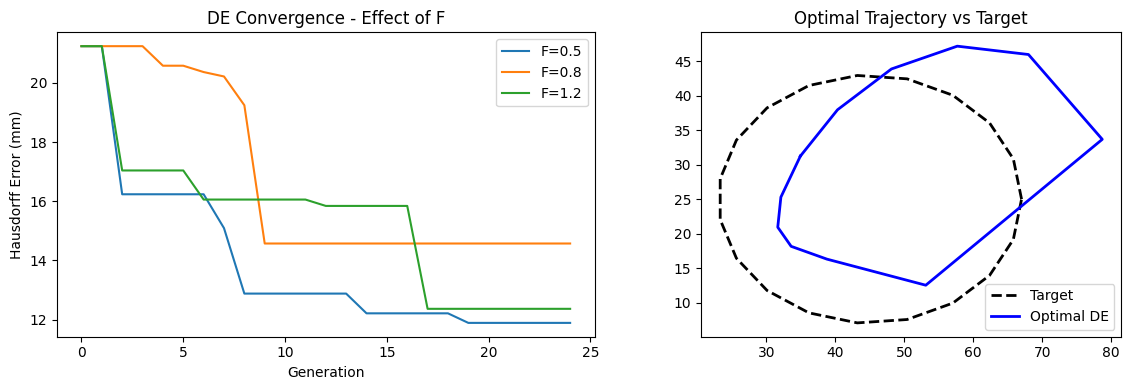

In [14]:
import builtins
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Convergence for different scale factor (F) values
for F_val, lbl in [(0.5, 'F=0.5'), (0.8, 'F=0.8'), (1.2, 'F=1.2')]:
    random.seed(3)
    p2 = LB + random.rand(N_POP, 3) * (UB - LB)
    h2 = []
    for gen in range(N_GEN):
        for i in range(N_POP):
            idxs = list(range(N_POP))
            idxs.remove(i)
            a_, b_, c_ = p2[random.choice(idxs, 3, replace=False)]

            mut = clip(a_ + F_val * (b_ - c_), LB, UB)
            cross = random.rand(3) < CR
            if not cross.any():
                cross[random.randint(3)] = True

            trial = where(cross, mut, p2[i])
            if fitness(trial) < fitness(p2[i]):
                p2[i] = trial

        h2.append(fitness(builtins.min(p2, key=fitness)))
    axes[0].plot(h2, label=lbl)

axes[0].set_xlabel('Generation')
axes[0].set_ylabel('Hausdorff Error (mm)')
axes[0].set_title('DE Convergence - Effect of F')
axes[0].legend()

# Optimal trajectory obtained versus target geometry
Cx, Cy = fourbar_coupler(best[0], best[1], best[2], D_F, th2v)
m = isfinite(Cx)

axes[1].plot(Px, Py, 'k--', lw=2, label='Target')
axes[1].plot(Cx[m], Cy[m], 'b-', lw=2, label='Optimal DE')
axes[1].set_aspect('equal')
axes[1].legend()
axes[1].set_title('Optimal Trajectory vs Target')

plt.tight_layout()
plt.show()